# NISAR Dual-Pol SAR Analysis: Cloude-Pottier H/alpha and Dual-Pol Intensity Decomposition

This notebook demonstrates two polarimetric analysis workflows applicable to **NISAR L-band dual-polarization (HH/HV) GSLC data**:

1. **Cloude-Pottier H/alpha Decomposition** -- eigenvalue-based separation of polarimetric entropy (H) and mean scattering angle (alpha) from the 2x2 covariance matrix [C2]. Designed for dual- and quad-pol coherent SAR data with any transmit polarization. Produces a 9-zone unsupervised classification of scattering mechanisms.

2. **Dual-Pol Intensity Decomposition (DPID)** -- a physically grounded, three-channel intensity analysis tailored for **linear HH/HV transmit/receive systems** such as NISAR. Builds RGB false-colour composites from co-pol (gamma_HH), cross-pol (gamma_HV), and their ratio, and derives a 5-class unsupervised land-cover map.

### Appropriate approaches for NISAR linear dual-pol (HH/HV)

- **Cloude-Pottier H/alpha** (Section 1): eigenvalue analysis of [C2] -- fully valid for any dual-pol configuration.
- **DPID** (Section 2): exploits the physically interpretable gamma_HH, gamma_HV intensities and their ratio.

::: {dropdown} Core Theoretical Polarimetry

#### 1. The 2x2 Covariance Matrix [C2] for Dual-Pol HH/HV

For a monostatic dual-pol SAR system transmitting H and receiving HH and HV, the complex scattering vector is **k** = [S_HH, S_HV]^T. After spatial averaging over a multi-look window, the **2x2 covariance matrix** is:

$$[C_2] = \langle \mathbf{k}\,\mathbf{k}^{*T} \rangle = \begin{bmatrix} \langle |S_{HH}|^2 \rangle & \langle S_{HH} S_{HV}^* \rangle \\ \langle S_{HV} S_{HH}^* \rangle & \langle |S_{HV}|^2 \rangle \end{bmatrix} = \begin{bmatrix} C_{11} & C_{12} \\ C_{12}^* & C_{22} \end{bmatrix}$$

Diagonal elements $C_{11} = \gamma^\circ_{HH}$ and $C_{22} = \gamma^\circ_{HV}$ are the co-pol and cross-pol backscatter intensities. $C_{12}$ is the complex cross-channel correlation; its magnitude $|C_{12}| = \sqrt{C_{11} \cdot C_{22}} \cdot |\gamma_{HH-HV}|$ where $\gamma_{HH-HV}$ is the HH-HV complex coherence.

#### 2. Cloude-Pottier H/alpha Decomposition (Section 1)

The [C2] matrix has two non-negative real eigenvalues $\lambda_1 \ge \lambda_2$ computed analytically:

$$\lambda_{1,2} = \frac{\text{Tr}([C_2]) \pm \sqrt{\text{Tr}([C_2])^2 - 4\,\text{Det}([C_2])}}{2}$$

Their pseudo-probabilities $P_i = \lambda_i / (\lambda_1 + \lambda_2)$ define the **Polarimetric Entropy**:

$$H = -\sum_{i=1}^{2} P_i \log_2 P_i \in [0, 1]$$

$H = 0$: one dominant scattering mechanism (e.g., specular surface). $H = 1$: two equally probable, incoherent mechanisms (e.g., dense random canopy).

The **Mean Scattering Angle** alpha is extracted from the eigenvectors:

$$\alpha = P_1\,\arctan\!\left(\frac{|\lambda_1 - C_{11}|}{|C_{12}|}\right) + P_2\,\arctan\!\left(\frac{|\lambda_2 - C_{11}|}{|C_{12}|}\right) \in [0^\circ, 90^\circ]$$

$\alpha \approx 0^\circ$: surface/Bragg. $\alpha \approx 45^\circ$: volume/random. $\alpha \approx 90^\circ$: dihedral/double-bounce.

*References: Cloude & Pottier (1996, 1997); Lee & Pottier (2009) ch. 4.*

#### 3. Dual-Pol Intensity Decomposition -- DPID (Section 2)

For linear HH/HV dual-pol, three physically interpretable intensity-domain quantities provide a complete first-order characterization (Moreira et al., 2013):

| Channel | Symbol | Physical Meaning |
|---------|--------|-----------------|
| Co-pol intensity | $\gamma^\circ_{HH} = C_{11}$ | Sensitive to specular surface + double-bounce |
| Cross-pol intensity | $\gamma^\circ_{HV} = C_{22}$ | Dominated by volume/random scatterers (vegetation) |
| Cross-pol ratio | $\text{DCP} = \gamma^\circ_{HV} / \gamma^\circ_{HH}$ | Degree of Cross-Polarization; low -> surface, high -> volume |

A false-colour RGB composite (R = gamma_HH, G = gamma_HV, B = DCP) gives:
- **Red areas**: high co-pol -- built-up structures, double-bounce.
- **Green areas**: high cross-pol -- dense vegetation, volume scattering.
- **Blue areas**: high co/cross ratio -- smooth surfaces, calm water.

Because only intensities and real-valued products are used, DPID is valid for any linear dual-pol configuration.

*References: Cloude (2010) ch. 3; Moreira et al. (2013).*

:::

## Overview

1. [Prerequisites](gslcifg-prereqs)
1. [Search for Data](gslcifg-search)
1. [Explore dataset structure](gslcifg-explore)
1. [Plotting the GSLC amplitudes as a RGB composite](gslcifg-plot-gslc)
1. [Cloude-Pottier H/alpha Decomposition](gslcifg-halpha)
1. [Dual-Pol Intensity Decomposition (DPID)](gslcifg-dpid)
1. [Comparing Both Decompositions](gslcifg-pol-comparison)
1. [Stokes Parameter Scatter Plot](gslcifg-stokes-scatterplot)
1. [Radar Forest Biomass Index (RFBI)](gslcifg-rfbi)
1. [Summary](gslcifg-summary)
1. [Resources and references](gslcifg-resources)

<hr>

(gslcifg-prereqs)=
## 1. Prerequisites

| Prerequisite | Importance | Notes |
| --- | --- | --- |
| [The `isce3` software environment for this cookbook](software_environment_docker.ipynb) | Necessary | |
| The visualization functions in `nisar_plot_utils.py` (util directory) | Necessary | |
| The polarization functions in `nisar_polsar.py` (util directory) | Necessary | |
| [Familiarity with xarray](https://docs.xarray.dev/en/stable/) | Helpful | |
| General knowledge of polarimetry | Helpful |

- **Rough Notebook Time Estimate**: 20 mins 

<hr>


In [1]:
import os
# Confirm the working directory: this should be the notebooks/ folder.
# If running from a different directory, the util_dir path in Cell 2 may need adjustment.
print("Working directory:", os.getcwd())


Working directory: /Users/ials/Documents/unal2025/PRA/ML/claudio/NISAR_Cookbook/notebooks


(gslcifg-search)=
## 2. Search for data

Use `asf_search` to find GSLC data.

### 2a. Start an ASF session

In [2]:
import os
import asf_search as asf
from datetime import datetime
from getpass import getpass

In [3]:
session = asf.ASFSession()
# Make sure you replace the token value below with a valid one
session.auth_with_token('your-token-value-should-be-here')

### 2b. Search for GSLC data with asf_search.search()
:::{tip} View all possible search parameters

There are many ASFSearchOptions parameters, in addition to those used in the search below. A complete list can be found here. :::

In [4]:
## define your own parameters
start_date = datetime(2025, 12, 10)
end_date = datetime(2025, 12, 31)
area_of_interest = "POLYGON((-76.2 8.13,-74.2 8.13,-74.2 9.26,-76.2 9.26,-76.2 8.13))" # POINT or POLYGON as WKT (well-known-text)

opts=asf.ASFSearchOptions(**{
    "maxResults": 250,
    "intersectsWith": area_of_interest,
    "start": start_date,
    "end": end_date,
    "processingLevel": [
        "GSLC"
    ],
    "dataset": [
        "NISAR"
    ],
    "productionConfiguration": [
        "PR"
    ],
    'session': session,
})

response = asf.search(opts=opts)
hdf5_files = response.find_urls(extension='.h5', directAccess=False)

# Extract and print the filenames 
filenames = [url.split('/')[-1] for url in hdf5_files]
print("\n".join(filenames))

NISAR_L2_PR_GSLC_008_011_D_084_4005_DHDH_A_20251216T232807_20251216T232841_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_008_011_D_084_4005_DHDH_A_20251216T232807_20251216T232841_X05009_N_F_J_001_QA_STATS.h5
NISAR_L2_PR_GSLC_008_011_D_085_4005_DHDH_A_20251216T232840_20251216T232914_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_008_011_D_085_4005_DHDH_A_20251216T232840_20251216T232914_X05009_N_F_J_001_QA_STATS.h5
NISAR_L2_PR_GSLC_009_011_D_084_4005_DHDH_A_20251228T232807_20251228T232841_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_009_011_D_084_4005_DHDH_A_20251228T232807_20251228T232841_X05009_N_F_J_001_QA_STATS.h5
NISAR_L2_PR_GSLC_009_011_D_085_4005_DHDH_A_20251228T232840_20251228T232915_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_009_011_D_085_4005_DHDH_A_20251228T232840_20251228T232915_X05009_N_F_J_001_QA_STATS.h5


### 2c. Filter the results

Note that the results include the `QA_STATS` files as well as the GSLC products. If you only want the GSLC data, you can remove the `QA_STATS` files with a pattern (regex) filter when calling `response.find_urls`

In [5]:
# Don't run this code cell if you wish to download the QA_STATS data

# Include include a negative lookahead for "QA_STATS"
pattern = r'^(?!.*QA_STATS).*'
# To include the static files, remove the `pattern=pattern` argument below
hdf5_files = response.find_urls(extension='.h5', pattern=pattern, directAccess=False)
# Extract and print the filenames 
filenames = [url.split('/')[-1] for url in hdf5_files]
print("\n".join(filenames))

NISAR_L2_PR_GSLC_008_011_D_084_4005_DHDH_A_20251216T232807_20251216T232841_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_008_011_D_085_4005_DHDH_A_20251216T232840_20251216T232914_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_009_011_D_084_4005_DHDH_A_20251228T232807_20251228T232841_X05009_N_F_J_001.h5
NISAR_L2_PR_GSLC_009_011_D_085_4005_DHDH_A_20251228T232840_20251228T232915_X05009_N_F_J_001.h5


### 2d. Download the data to a specified directory

In [6]:
from pathlib import Path
# change your Path as needed
data_dir = Path.home() / "Cordoba_data"
data_dir.mkdir(exist_ok=True)
print(f'data_dir: {data_dir}')

asf.download_urls(hdf5_files, data_dir, session=session, processes=4)

data_dir: /Users/ials/Cordoba_data


/Users/ials/miniconda3/lib/python3.12/site-packages/asf_search/download/download.py:66: UserWarning: File already exists, skipping download: /Users/ials/Cordoba_data/NISAR_L2_PR_GSLC_008_011_D_085_4005_DHDH_A_20251216T232840_20251216T232914_X05009_N_F_J_001.h5
  warnings.warn(f'File already exists, skipping download: {os.path.join(path, filename)}')
/Users/ials/miniconda3/lib/python3.12/site-packages/asf_search/download/download.py:66: UserWarning: File already exists, skipping download: /Users/ials/Cordoba_data/NISAR_L2_PR_GSLC_009_011_D_084_4005_DHDH_A_20251228T232807_20251228T232841_X05009_N_F_J_001.h5
  warnings.warn(f'File already exists, skipping download: {os.path.join(path, filename)}')
/Users/ials/miniconda3/lib/python3.12/site-packages/asf_search/download/download.py:66: UserWarning: File already exists, skipping download: /Users/ials/Cordoba_data/NISAR_L2_PR_GSLC_008_011_D_084_4005_DHDH_A_20251216T232807_20251216T232841_X05009_N_F_J_001.h5
  warnings.warn(f'File already exis

(gslcifg-explore)=
## 3. Explore dataset structure

<br>

In [15]:
import sys
from pathlib import Path

# ── Add the Cookbook util directory to the Python path ─────────────────────────
# The CONTRIBUTING guide keeps all reusable Python code under util/.
# Path.cwd() is the notebooks/ directory when running in Jupyter, so
# .parent / "util" resolves to the sibling util/ directory.
util_dir = Path.cwd().parent / "util"
sys.path.insert(0, str(util_dir))
# ── Plotting functions ─────────────────────────────────────────────────────────
import nisar_plot_utils as npu
# Available: npu.plot_gslc_overview, npu.plot_halpha_maps,
#            npu.plot_decomposition_histograms, npu.plot_cloude_pottier_zones,
#            npu.plot_dual_pol_rgb, npu.plot_dual_pol_classification,
#            npu.plot_decompositions_comparison, npu.plot_stokes_distribution

# ── Standard scientific libraries ──────────────────────────────────────────────
import os
import numpy as np
import h5py
import hdf5plugin   # MUST precede h5py to activate NISAR decompression plugins
import matplotlib.pyplot as plt

In [43]:
# ── Path to the NISAR GSLC HDF5 file ─────────────────────────────────────────
# Update this path to point to your local copy of the NISAR GSLC product.
# NISAR filename convention:
#   GSLC_009_011_D  -> Geocoded SLC, orbit 9, relative orbit 11, descending
#   DHDH_A          -> Dual-pol HH+HV, L-band (LSAR)
#   20251228        -> Acquisition date
gslc_file_path = (
    "/Users/ials/Cordoba_data/"
    "NISAR_L2_PR_GSLC_009_011_D_084_4005_DHDH_A_20251228T232807_20251228T232841_X05009_N_F_J_001.h5"
)

In [44]:
# ── Explore available calibration datasets in the HDF5 ────────────────────────
# visititems() walks the HDF5 tree recursively and calls print_structure
# for every node, letting you verify which datasets are present before processing.
def print_structure(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"  {name}  |  shape: {obj.shape}  |  dtype: {obj.dtype}")

with h5py.File(gslc_file_path, 'r') as f:
    cal_group = f['/science/LSAR/GSLC/metadata/calibrationInformation']
    print("Calibration datasets in this GSLC product:")
    cal_group.visititems(print_structure)


Calibration datasets in this GSLC product:
  crosstalk/projection  |  shape: ()  |  dtype: uint32
  crosstalk/rxHorizontalCrosspol  |  shape: (332, 339)  |  dtype: complex64
  crosstalk/rxVerticalCrosspol  |  shape: (332, 339)  |  dtype: complex64
  crosstalk/txHorizontalCrosspol  |  shape: (332, 339)  |  dtype: complex64
  crosstalk/txVerticalCrosspol  |  shape: (332, 339)  |  dtype: complex64
  crosstalk/xCoordinates  |  shape: (339,)  |  dtype: float64
  crosstalk/yCoordinates  |  shape: (332,)  |  dtype: float64
  frequencyA/HH/differentialDelay  |  shape: ()  |  dtype: float64
  frequencyA/HH/differentialPhase  |  shape: ()  |  dtype: float64
  frequencyA/HH/rfiLikelihood  |  shape: ()  |  dtype: float64
  frequencyA/HH/scaleFactor  |  shape: ()  |  dtype: float64
  frequencyA/HH/scaleFactorSlope  |  shape: ()  |  dtype: float64
  frequencyA/HV/differentialDelay  |  shape: ()  |  dtype: float64
  frequencyA/HV/differentialPhase  |  shape: ()  |  dtype: float64
  frequencyA/HV/rfiL

(gslcifg-plot-gslc)=
## 4. Plotting the GSLC amplitudes as a RGB composite

<br>

In [45]:
import sys
from pathlib import Path

# ── Add the Cookbook util directory to the Python path ─────────────────────────
# The CONTRIBUTING guide keeps all reusable Python code under util/.
# Path.cwd() is the notebooks/ directory when running in Jupyter, so
# .parent / "util" resolves to the sibling util/ directory.
util_dir = Path.cwd().parent / "util"
sys.path.insert(0, str(util_dir))

# ── Processing functions (speckle filter, decompositions, export) ──────────────
from nisar_polsar import (
    refined_lee_filter,
    compute_cloude_pottier,
    classify_cloude_pottier,
    display_zone_breakdown,
    export_zones_geotiff,
    compute_dpid,
    classify_dpid,
    display_dpid_breakdown,
    export_dpid_geotiff,
    compute_rfbi,
    export_rfbi_geotiff,
)

Opening file and downsampling by factor 20...


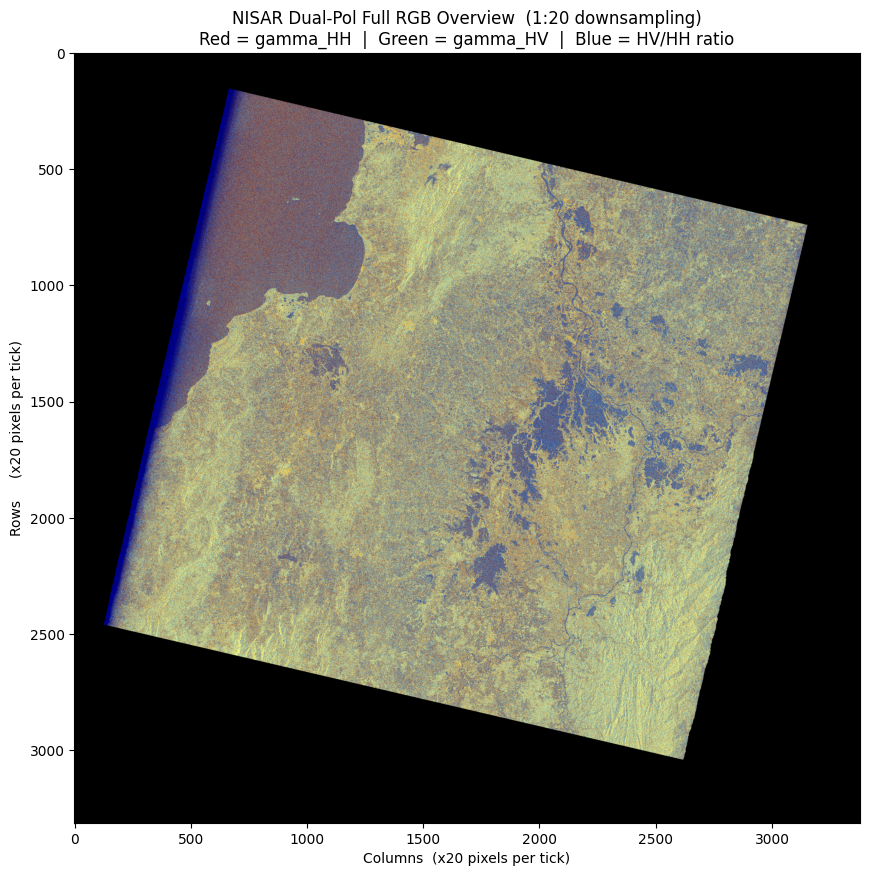

In [46]:
# ── Full-scene RGB overview ────────────────────────────────────────────────────
# plot_gslc_overview() is defined in util/nisar_plot_utils.py.
# It reads the entire scene at 1:step resolution and displays a false-colour
# composite (R=gamma_HH, G=gamma_HV, B=DCP) for quick spatial orientation.
# step=20 reduces a 30 000 x 30 000 image to 1 500 x 1 500 for fast rendering.
npu.plot_gslc_overview(gslc_file_path, step=20)


(gslcifg-halpha)=
## 5. Cloude-Pottier H/alpha Decomposition

The cells below implement:
1. Speckle filtering with a Refined Lee filter on each element of [C2].
2. Closed-form 2x2 eigenvalue decomposition to produce H and alpha maps.
3. Histograms of H and alpha distributions across the AOI.
4. 9-zone unsupervised classification adapted to dual-pol thresholds.
5. GeoTIFF export with correct spatial alignment.

### 5a. Refined Lee Speckle Filter

SAR images suffer from **speckle** -- a multiplicative noise produced by coherent interference of many random scatterers within a resolution cell. The **Refined Lee filter** (Lee, 1981) reduces speckle while preserving edges by adapting the degree of smoothing to the local spatial variance:

$$\hat{I}(x) = \bar{I}(x) + k(x)\bigl[I(x) - \bar{I}(x)\bigr], \quad k = \frac{\sigma_L^2}{\sigma_L^2 + \sigma_n^2}$$

In homogeneous regions $k \to 0$ (heavy smoothing); at edges $k \to 1$ (pixel preserved). The covariance elements $C_{11}$, $C_{22}$, $\text{Re}\{C_{12}\}$, $\text{Im}\{C_{12}\}$ are filtered independently before eigenvalue decomposition.

*Reference: Lee, J.S. (1981)*
<br>

In [47]:
# ── Cloude-Pottier H/alpha Decomposition ─────────────────────────────────────
# compute_cloude_pottier() is defined in util/nisar_polsar.py.
# Steps performed inside:
#   1. Read complex HH and HV SLC bands from the HDF5 (AOI slice only)
#   2. Apply gamma-nought calibration: gamma0 = |S|^2 / scaleFactor^2
#   3. Build the 2x2 covariance matrix [C2]
#   4. Speckle-filter each element with the Refined Lee filter
#   5. Solve the 2x2 eigenvalue problem analytically (quadratic formula)
#   6. Compute Entropy H = -sum(Pi * log2(Pi)) and Mean Scattering Angle alpha
#
# Returns two 2-D float32 arrays covering the AOI:
#   H     -- Polarimetric Entropy in [0, 1]
#            (0 = one dominant mechanism; 1 = two equally probable mechanisms)
#   alpha -- Mean Scattering Angle in degrees [0, 90]
#            (0 = surface; 45 = volume; 90 = double-bounce)


Full dataset: 66240 rows x 67536 cols
AOI: rows [20000:30000], cols [20000:30000]
Reading HH and HV bands...
Scale factors  HH: 3.7405e+00  HV: 3.7405e+00
Building [C2] covariance matrix elements...
Applying Refined Lee filter to covariance elements...
Computing eigenvalues...
Computing entropy H...
Computing mean scattering angle alpha...


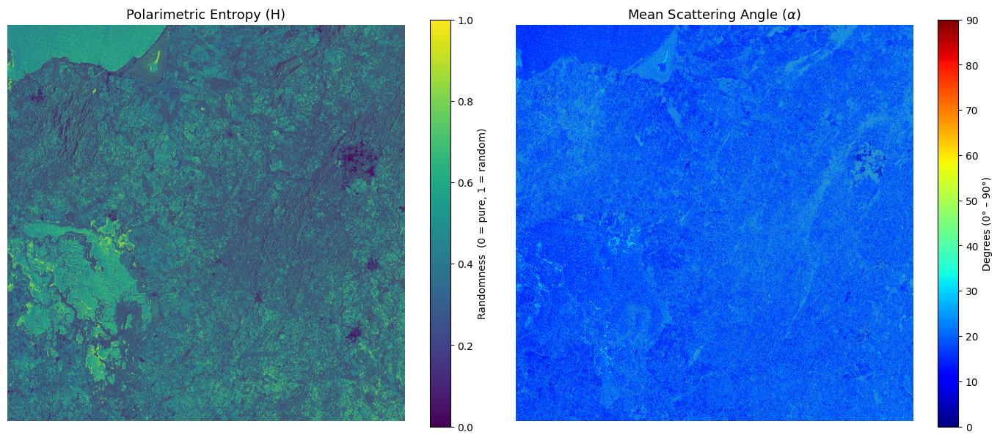

H range:     -1.549 -- 1.000
alpha range: 0.0 -- 87.8 degrees


In [48]:
# ── Define the Area of Interest and run the decomposition ─────────────────────
# A full NISAR GSLC scene is ~30 000 x 30 000 pixels.  The AOI below selects
# a 10 000 x 10 000 tile to keep RAM usage tractable on a workstation.
# Adjust (row_start, row_end, col_start, col_end) to target any region of the scene.
my_aoi = (20000, 30000, 20000, 30000)

H, alpha = compute_cloude_pottier(gslc_file_path, window_size=5, aoi_window=my_aoi)
npu.plot_halpha_maps(H, alpha)

print(f"H range:     {H.min():.3f} -- {H.max():.3f}")
print(f"alpha range: {alpha.min():.1f} -- {alpha.max():.1f} degrees")


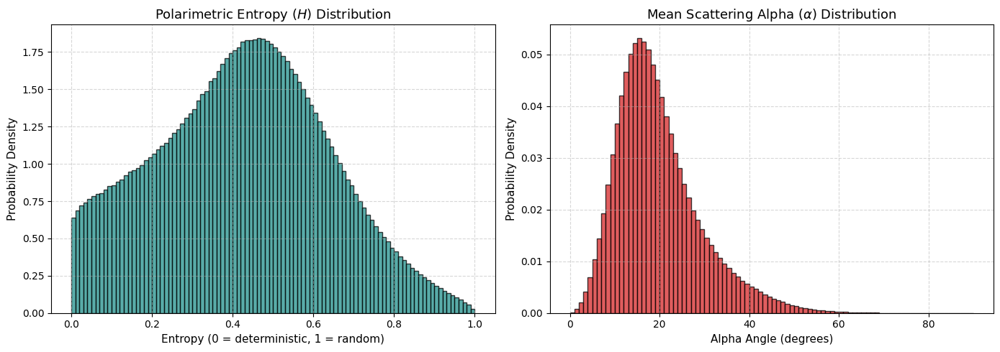

In [49]:
# ── H / alpha diagnostic histograms ──────────────────────────────────────────
# H peaked near 0:    one dominant scattering mechanism (water, bare soil)
# H peaked near 0.8+: two mixed mechanisms (dense forest, crops)
# alpha peaked 0-25:  surface scattering dominates
# alpha peaked 40-50: volume scattering dominates (tropical forest at L-band)
# alpha peaked >60:   double-bounce contribution (urban, flooded stems)
npu.plot_decomposition_histograms(H, alpha, step=5)


### 5b. Cloude-Pottier unsupervised classification zones

In [50]:
# ── Cloude-Pottier Unsupervised Classification ─────────────────────────────
# classify_cloude_pottier is defined in util/nisar_polsar.py.
# Assign each pixel to one of nine H/alpha scattering zones using the
# dual-pol optimal dividing lines empirically derived for HH-HV SAR by
# Ji & Wu (2015, Table 2), rather than the classical full-polarimetric
# Cloude & Pottier (1997) thresholds (H = 0.5/0.9, alpha = 42.5/47.5),
# which are not valid outside the full-pol [T3] feasible region.

# Zone layout matches Ji & Wu (2015), Figure 1 (Z1 = lowest entropy/alpha,
# Z9 = highest entropy/alpha), NOT the earlier ad hoc numbering of this
# module:
#        Low H  (< l1=0.66):        Z1 surface | Z2 dipole | Z3 multiple
#       Medium H (l1-l2=0.66-0.93): Z4 surface | Z5 dipole | Z6 multiple
#       High H (> l2=0.93):                    Z8 dipole | Z9 multiple


Classifying pixels into 9 H/alpha zones (Ji & Wu 2015 HH-HV dividing lines)...
Applying 3x3 spatial median filter...


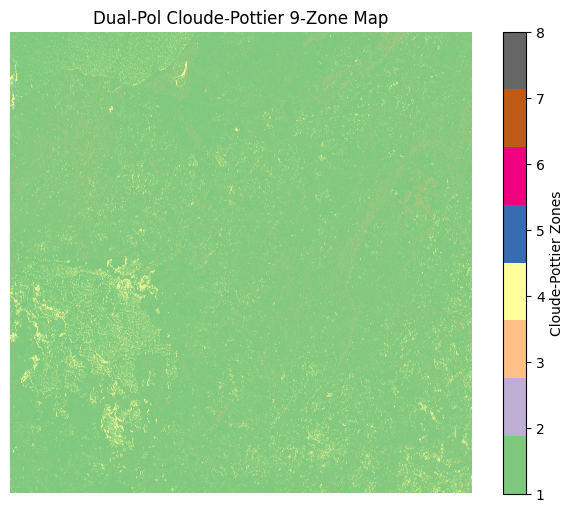

Zone array shape: (10000, 10000)  |  unique labels: [np.uint8(1), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(8)]


In [68]:
zones = classify_cloude_pottier(H, alpha, apply_filter=True)

# Plot manually to gain absolute control over the aesthetics
plt.figure(figsize=(8, 6))
plt.imshow(zones, cmap="Accent")  # Change "tab10" to your preferred map
plt.colorbar(label="Cloude-Pottier Zones")
plt.title("Dual-Pol Cloude-Pottier 9-Zone Map")
plt.axis("off")  # Optional: hides pixel coordinates axes if preferred
plt.show()

# 3. Print information
print(f"Zone array shape: {zones.shape}  |  unique labels: {sorted(set(zones.flatten()))}")


### 5c. Statistics of classification zones

In [52]:
# ── Zone area statistics ───────────────────────────────────────────────────────
# display_zone_breakdown() counts pixels per zone and computes coverage %.
# To convert to km^2: multiply pixel count by (pixel_spacing_m)^2 / 1e6
# For NISAR GSLC at 10 m posting: 1 pixel = 100 m^2 = 1e-4 km^2.
display_zone_breakdown(zones)


Total valid pixels: 100,000,000


,Description,Pixels,Coverage (%)
Zone,,,
1,Z1 High-H Double-Bounce (flooded forest / dens...,"91,664,665",91.66
2,Z2 High-H Volume (dense forest canopy),0,0.00
3,Z3 High-H Surface (complex rough surfaces),"3,541,432",3.54
4,Z4 Med-H Double-Bounce (urban / oriented struc...,"4,754,903",4.75
5,Z5 Med-H Volume (vegetation / crops),"20,480",0.02
6,Z6 Med-H Surface (rough soil / moderate water),767,0.00
7,Z7 Low-H Double-Bounce (isolated buildings),0,0.00
8,Z8 Low-H Dipole (sparse vegetation / oriented ...,"17,753",0.02
9,Z9 Low-H Surface (calm water / smooth bare gro...,0,0.00


### 5d. Export H/alpha zones to GeoTIFF

In [53]:
# ── Export H/alpha zone map to GeoTIFF ────────────────────────────────────────
# export_zones_geotiff() is defined in util/nisar_polsar.py.
# It reads the geographic metadata (CRS, pixel spacing, coordinates) from the
# source HDF5 file, builds an affine transform, and writes a uint8 GeoTIFF
# with nodata=0 (background pixels shown as transparent in QGIS / ArcGIS).
output_tiff = "/Users/ials/Cordoba_data/NISAR_CloudePottier_Cordoba.tif"
export_zones_geotiff(zones, gslc_file_path, output_tiff, aoi_window=my_aoi)


Writing zone GeoTIFF to: /Users/ials/Cordoba_data/NISAR_CloudePottier_Cordoba.tif
Done.


(gslcifg-dpid)=
## 6. Dual-Pol Intensity Decomposition (DPID)

The DPID exploits three physically interpretable intensity channels from linear HH/HV dual-pol data:

| Band | Expression | Scene diagnostic |
|------|-----------|-----------------|
| R | gamma_HH | Co-pol backscatter; dominant for oriented surfaces and double-bounce targets |
| G | gamma_HV | Cross-pol backscatter; dominant for volume scatterers (forest, crops) |
| B | DCP = gamma_HV / gamma_HH | Degree of Cross-Polarization; low for smooth surfaces, high for dense vegetation |

### Physical interpretation of the RGB composite

- **Red pixels**: high gamma_HH, low gamma_HV -- urban double-bounce, bare soil at steep incidence.
- **Green pixels**: high gamma_HV -- dense forest canopy, strongly depolarizing targets.
- **Blue pixels**: high DCP -- moderate-density vegetation or agricultural fields with dominant cross-pol fraction.
- **Dark pixels**: very low total power -- calm water reflects specularly away from the radar.

### Unsupervised classification

Five scene classes are derived by percentile-based thresholding on (sigma_span, gamma_HH, DCP):

1. Calm Water -- very low total power (SPAN < p10)
2. Bare Soil / Open -- moderate-to-high HH, very low DCP
3. Dense Vegetation / Forest -- high HV, high DCP (> 0.5)
4. Urban / Built-up -- very high HH (> p90), low DCP (< 0.4)
5. Wetlands / Flooded Vegetation -- elevated both HH and HV

Thresholds are scene-adaptive (computed from data percentiles) and generalize across dates and regions.

*References: Cloude (2010) ch. 3; Moreira et al. (2013).*
<br>

### 6a. Dual-Pol Intensity Decomposition (DPID)

Reading HH and HV bands + calibration factors...
Scale factors  HH: 3.7405e+00  HV: 3.7405e+00
Applying Refined Lee filter...


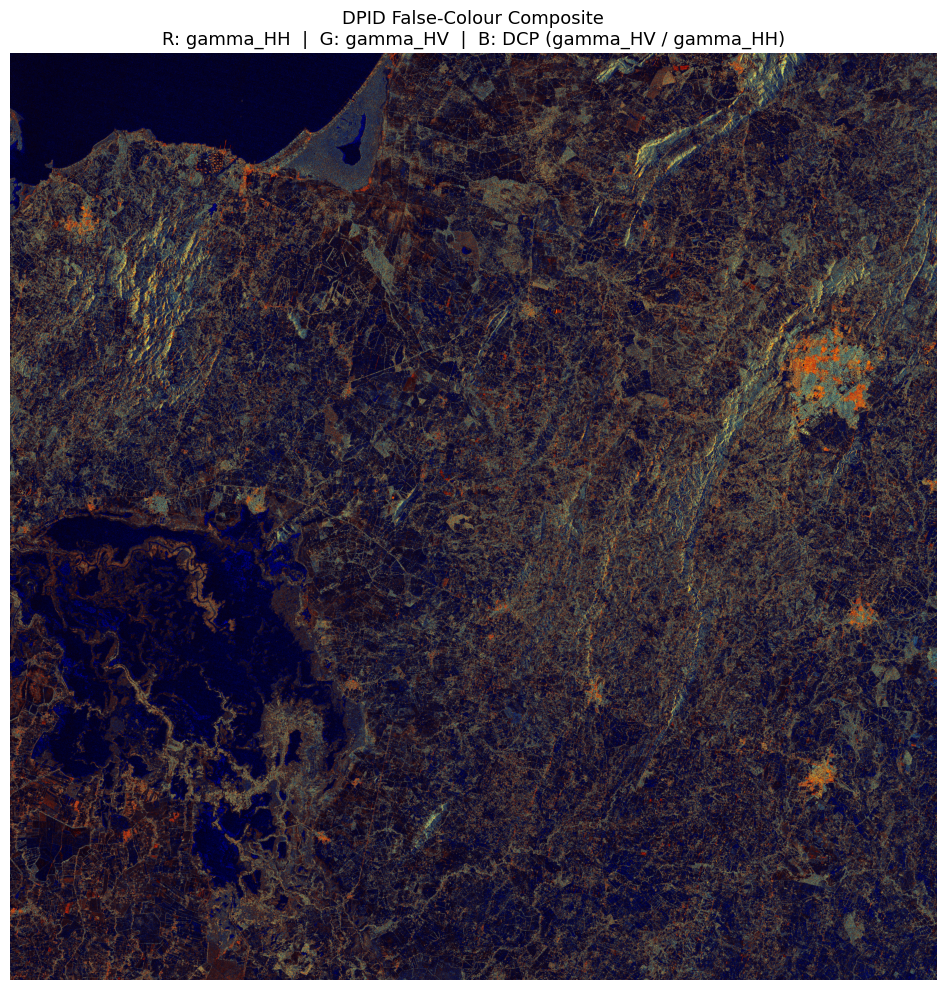

gamma0_HH range: 4.137e-05 -- 2.123e+02
gamma0_HV range: 1.878e-06 -- 8.689e+00
DCP ratio range: 0.000 -- 1.000


In [54]:
# ── Dual-Pol Intensity Decomposition (DPID) ───────────────────────────────────
# compute_dpid() is defined in util/nisar_polsar.py.
# It reads the complex HH and HV bands, applies gamma-nought calibration, runs
# the Refined Lee speckle filter, and returns three 2-D float32 arrays:
#
#   gamma0_HH  -- co-pol backscatter (high for surfaces and double-bounce targets)
#   gamma0_HV  -- cross-pol backscatter (high for volume / vegetation)
#   dcp_ratio  -- Degree of Cross-Polarization = gamma0_HV / gamma0_HH in [0, 1]
#
# These channels are physically valid for any linear dual-pol system and form
# an RGB false-colour composite (R=HH, G=HV, B=DCP) that distinguishes
# vegetation, bare soil, water, and urban areas at L-band.
gamma0_HH, gamma0_HV, dcp_ratio = compute_dpid(
    gslc_file_path, window_size=5, aoi_window=my_aoi)

npu.plot_dual_pol_rgb(gamma0_HH, gamma0_HV, dcp_ratio,
                      title=("DPID False-Colour Composite\n"
                             "R: gamma_HH  |  G: gamma_HV  |  B: DCP (gamma_HV / gamma_HH)"))

print(f"gamma0_HH range: {gamma0_HH.min():.3e} -- {gamma0_HH.max():.3e}")
print(f"gamma0_HV range: {gamma0_HV.min():.3e} -- {gamma0_HV.max():.3e}")
print(f"DCP ratio range: {dcp_ratio.min():.3f} -- {dcp_ratio.max():.3f}")


### 6b. DPID Unsupervised Classification

The five-class classification applies percentile thresholds to SPAN, gamma_HH, and DCP.
Thresholds are computed from the data itself, so the classifier adapts to different scenes
without manual tuning.

**Class assignment logic (in order of priority):**

| Priority | Class | Condition |
|----------|-------|-----------|
| 5 (default) | Bare Soil / Open Land | baseline assignment for finite pixels |
| 3 | Dense Vegetation | DCP > 0.5 AND gamma_HV > p50_HV |
| 5 overridden | Wetlands | gamma_HH > p60 AND gamma_HV > p60_HV |
| 4 | Urban / Built-up | gamma_HH > p90 AND DCP < 0.4 |
| 1 (highest) | Calm Water | SPAN < p10 (overrides all) |


In [55]:
# ── DPID five-class classification ────────────────────────────────────────────
# classify_dpid() is defined in util/nisar_polsar.py.
# It applies scene-adaptive percentile thresholds to assign each pixel to one
# of five land-cover classes:
#
#   1  Calm Water       -- lowest total power (specular, low SPAN)
#   2  Bare Soil / Open -- default; moderate HH, low DCP
#   3  Dense Vegetation -- high DCP and significant HV power
#   4  Urban / Built-up -- very high HH, low DCP (corner-reflector double-bounce)
#   5  Wetlands         -- both HH and HV elevated simultaneously
dpid_classes = classify_dpid(gamma0_HH, gamma0_HV, dcp_ratio)


### 6c. Visualise and tabulate DPID classes

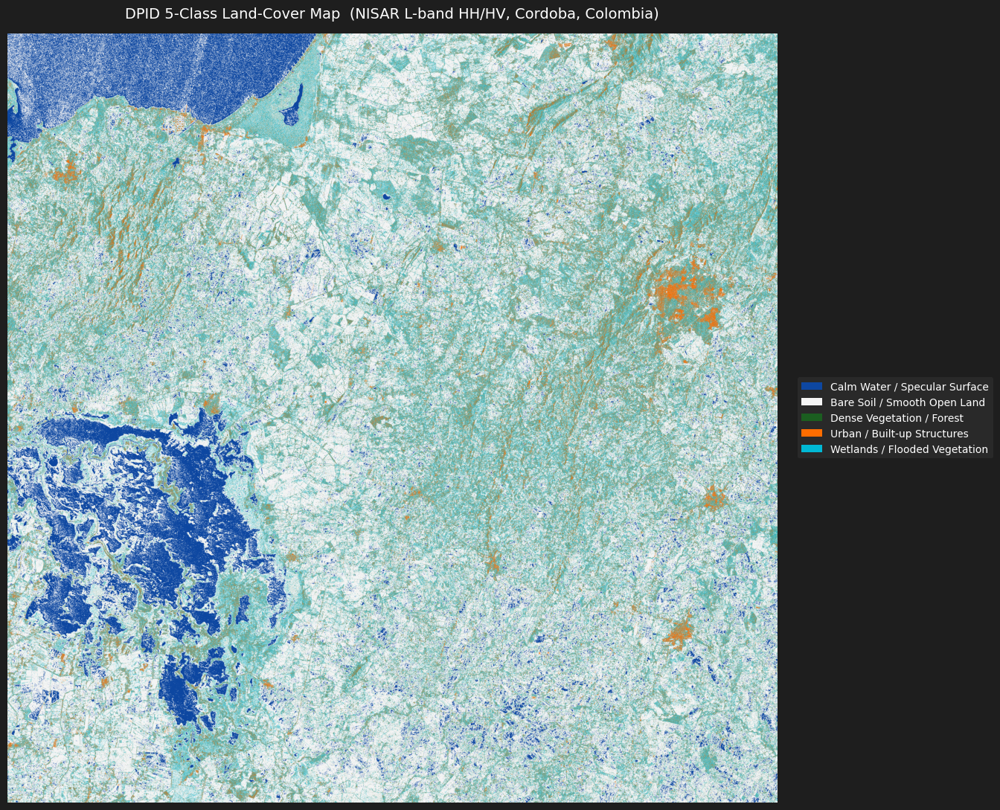

Total valid pixels: 100,000,000


,Description,Pixels,Coverage (%)
Class,,,
1,Calm Water,"9,999,996",10.00
2,Bare Soil / Open Land,"57,100,191",57.10
3,Dense Vegetation,"3,339,660",3.34
4,Urban / Built-up,"9,276,968",9.28
5,Wetlands,"20,283,185",20.28


In [56]:
# ── Visualise and tabulate DPID classes ───────────────────────────────────────
npu.plot_dual_pol_classification(
    dpid_classes,
    title="DPID 5-Class Land-Cover Map  (NISAR L-band HH/HV, Cordoba, Colombia)")
display_dpid_breakdown(dpid_classes)


### 6d. Export DPID channels to a GeoTIFF

In [57]:
# ── Export DPID channels to a 3-band float32 GeoTIFF ─────────────────────────
# export_dpid_geotiff() is defined in util/nisar_polsar.py.
# Band 1 = gamma0_HH  |  Band 2 = gamma0_HV  |  Band 3 = DCP ratio
# Float32 preserves the full dynamic range needed for downstream analysis
# (biomass regression, change detection, or machine learning feature extraction).
output_dpid = "/Users/ials/Cordoba_data/NISAR_DPID_Cordoba.tif"
export_dpid_geotiff(gamma0_HH, gamma0_HV, dcp_ratio,
                    gslc_file_path, output_dpid, aoi_window=my_aoi)


Writing DPID GeoTIFF to: /Users/ials/Cordoba_data/NISAR_DPID_Cordoba.tif
Done.


(gslcifg-pol-comparison)=
## 7. Comparing Both Decompositions

The side-by-side panel shows:
- **Left**: DPID false-colour composite (intensity-domain, valid for NISAR linear HH/HV).
- **Right**: Cloude-Pottier 9-zone classification (eigenvalue-domain, valid for any dual/quad-pol).

### What to look for

| Landscape type | DPID composite | Cloude-Pottier zones |
|----------------|----------------|----------------------|
| Calm water | Near-black (low SPAN) | Zone 9 (Low-H surface) |
| Dense forest | Bright green (gamma_HV dominant) | Zone 1 or 2 (High-H volume) |
| Urban / built-up | Bright red (gamma_HH dominant) | Zone 4 or 7 (double-bounce) |
| Cropped fields | Mixed green / dark | Zone 5 or 8 (volume / dipole) |
| Flooded vegetation | Yellow (both channels elevated) | Zone 1 (High-H double-bounce) |

The DPID provides a continuous, physically interpretable colour space; Cloude-Pottier gives
discrete, entropy-stratified classes useful for area statistics and change detection.
<br>

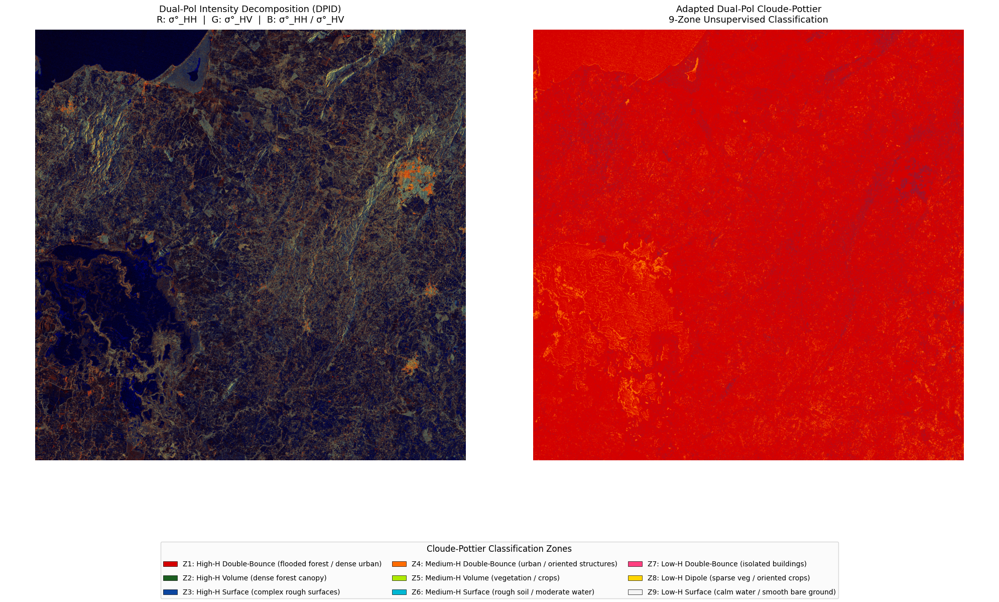

In [58]:
# ── Side-by-side comparison: DPID vs Cloude-Pottier ──────────────────────────
# Corresponding features to cross-check:
#   DPID near-black   <->  C-P Z9 (Low-H surface: calm water)
#   DPID bright-green <->  C-P Z2 (High-H volume: dense forest)
#   DPID bright-red   <->  C-P Z7 (Low-H double-bounce: isolated buildings)
# Agreement validates both decompositions; divergence indicates where the
# DPID intensity simplification differs from full eigenvalue analysis.
npu.plot_decompositions_comparison(gamma0_HH, gamma0_HV, dcp_ratio, zones)


(gslcifg-stokes-scatterplot)=
## 8. Stokes Parameter Scatter Plot (S1 vs S2)

For a linear HH/HV system the two experimentally accessible Stokes parameters with direct
physical meaning are:

$$S_1 = \langle |S_{HH}|^2 \rangle - \langle |S_{HV}|^2 \rangle \quad \text{(co-pol vs cross-pol power balance)}$$
$$S_2 = 2\,\text{Re}\langle S_{HH} S_{HV}^* \rangle \quad \text{(real part of co/cross-pol correlation)}$$

**Note on S3:** $S_3 = 2\,\text{Im}\langle S_{HH} S_{HV}^* \rangle$ is numerically computable for linear dual-pol data but lies outside the scope of this notebook. The focus here is on $S_1$ and $S_2$, which have unambiguous physical interpretations for a linearly polarised transmit wave.

A density scatter plot of (S1, S2) reveals three main polarimetric regimes:
- **S1 >> 0 (right)**: co-pol dominated -- surface scattering, bare soil.
- **S1 ~ 0 (centre)**: balanced -- dense vegetation (random volume scattering).
- **|S2| large**: coherent cross-channel correlation -- oriented/structured targets.
<br>

Reading sub-sampled data (1 in 20^2 = 1 in 400 pixels)...
Plotting 250,000 valid polarisation states...


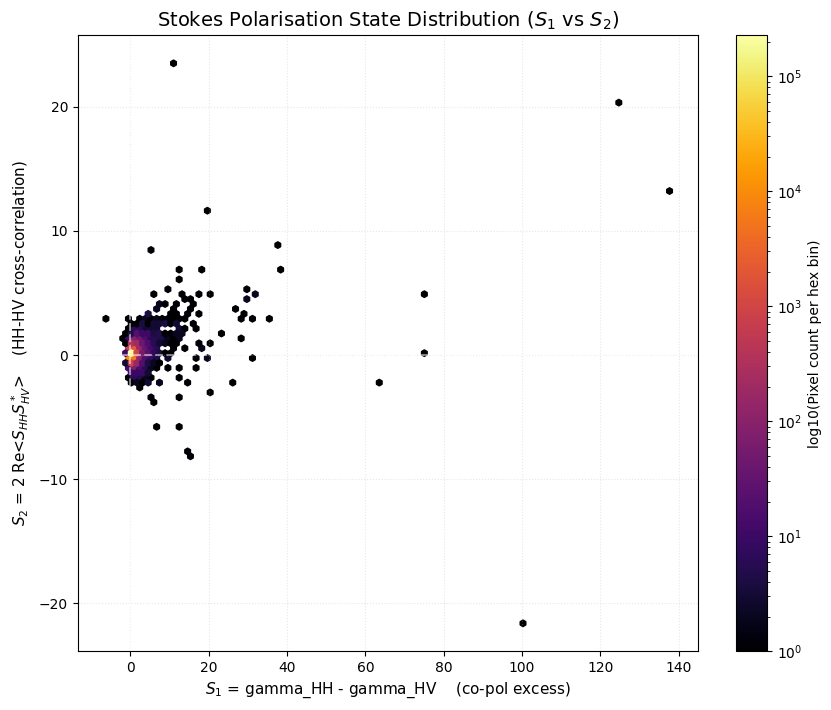

In [59]:
# ── Stokes parameter density scatter plot ─────────────────────────────────────
# plot_stokes_distribution() is defined in util/nisar_plot_utils.py.
# It computes S1 (co-pol / cross-pol power balance) and S2 (HH-HV cross-correlation)
# on a sub-sampled subset of the AOI and renders a hexbin density map.
# step=20 reads 1 in 400 pixels -- fast and statistically representative.
npu.plot_stokes_distribution(gslc_file_path, window_size=5, aoi_window=my_aoi, step=20)


(gslcifg-rfbi)=
## 9. Radar Forest Biomass Index (RFBI)

The RFBI is a normalized cross-pol fraction, masked to remove water and urban pixels:

$$\text{RFBI} = \frac{\gamma^\circ_{HV}}{\gamma^\circ_{HH} + \gamma^\circ_{HV}} \in [0, 1]$$

At L-band, $\gamma^\circ_{HV}$ is dominated by volume scattering from leaves, branches, and
trunks (Moreira et al., 2013). RFBI therefore serves as a proxy for canopy volume density:
values near 1 indicate closed-canopy tropical forest; values near 0 indicate water, bare soil,
or urban areas.

*Reference: Mitchard, E.T.A. et al. (2012)*
<br>

Computing RFBI = gamma0_HV / (gamma0_HH + gamma0_HV) ...


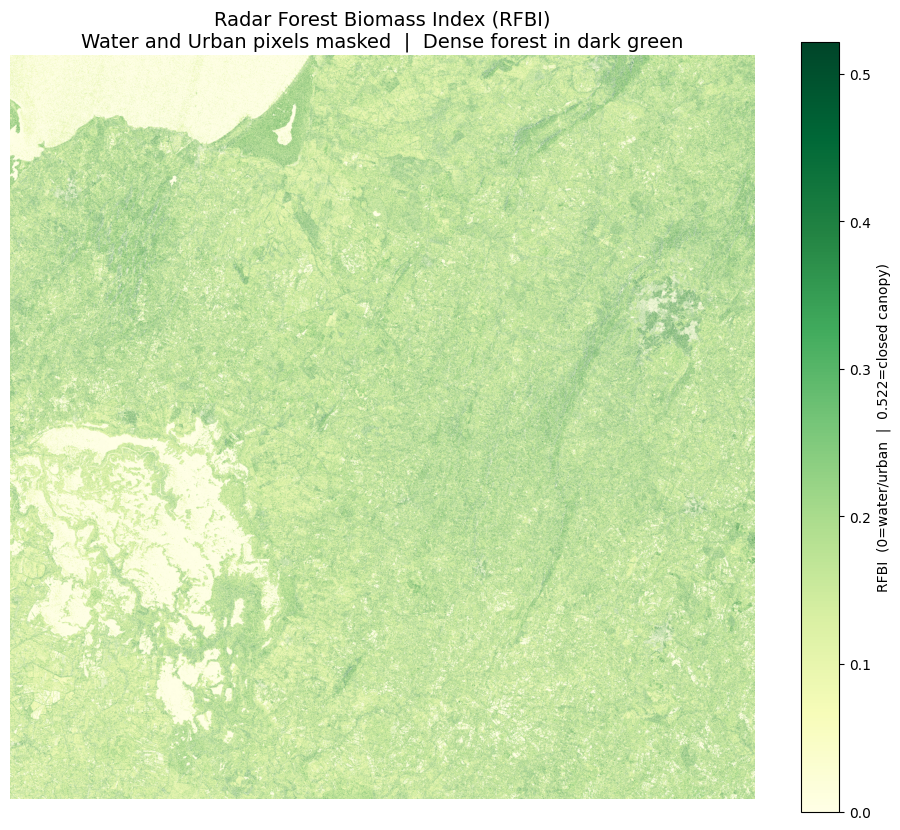

RFBI stats (canopy pixels only):  mean=0.174  median=0.138  std=0.115


In [60]:
# ── Radar Forest Biomass Index (RFBI) ─────────────────────────────────────────
# compute_rfbi() is defined in util/nisar_polsar.py.
# RFBI = gamma0_HV / (gamma0_HH + gamma0_HV) in [0, 1]
# At L-band, the cross-pol channel captures volume scattering from canopy elements;
# RFBI is therefore a proxy for canopy density:
#   ~ 0.0 -> water, bare soil, asphalt (masked to nodata=0)
#   ~ 0.5 -> moderately dense forest
#   ~ 0.8 -> closed-canopy tropical forest
rfbi_map = compute_rfbi(gamma0_HH, gamma0_HV)

import matplotlib.pyplot as plt
valid = rfbi_map[rfbi_map > 0.05]
display_max = float(np.percentile(valid, 98)) if valid.size > 0 else 1.0
plt.figure(figsize=(12, 10))
im = plt.imshow(rfbi_map, cmap='YlGn', vmin=0.0, vmax=display_max, origin='upper')
plt.title("Radar Forest Biomass Index (RFBI)\n"
          "Water and Urban pixels masked  |  Dense forest in dark green", fontsize=14)
plt.gcf().colorbar(im, label=f"RFBI  (0=water/urban  |  {display_max:.3f}=closed canopy)")
plt.axis('off')
plt.show()

if valid.size > 0:
    print(f"RFBI stats (canopy pixels only):  mean={valid.mean():.3f}  "
          f"median={float(np.median(valid)):.3f}  std={valid.std():.3f}")


In [61]:
# ── Export RFBI to single-band float32 GeoTIFF ────────────────────────────────
# export_rfbi_geotiff() is defined in util/nisar_polsar.py.
# nodata=0.0 flags masked water/urban pixels as transparent in QGIS.
# Open with the 'YlGn' colour ramp (yellow=low, dark green=high biomass).
output_rfbi = "/Users/ials/Cordoba_data/Forest_Biomass_Index_Cordoba.tif"
export_rfbi_geotiff(rfbi_map, gslc_file_path, output_rfbi, aoi_window=my_aoi)


Writing RFBI GeoTIFF to: /Users/ials/Cordoba_data/Forest_Biomass_Index_Cordoba.tif
Done.


(gslcifg-summary)=
## 10. Summary

You have now learned how to create a dual-polarization scattering matrix from a NISAR GSLC product. This workflow illustrated two polarimetric analysis workflows: (i) a Cloude-Pottier H/alpha Decomposition; and (ii) a
Dual-Pol Intensity Decomposition (DPID). Furthermore, it described how to obtain a  Radar Forest Biomass Index (RFBI).

<br>

(gslcifg-resources)=
## 11. Resources and references

- Cloude, S.R. and Pottier, E. (1996). A review of target decomposition theorems in radar polarimetry. *IEEE Transactions on Geoscience and Remote Sensing*, 34(2), 498-518.
- Cloude, S.R. and Pottier, E. (1997). An entropy based classification scheme for land applications of polarimetric SAR. *IEEE Transactions on Geoscience and Remote Sensing*, 35(1), 68-78.
- Cloude, S.R. (2010). *Polarisation: Applications in Remote Sensing*. Oxford University Press.
- Ji, K. and Wu, Y. (2015). Scattering mechanism extraction by a modified Cloude-Pottier decomposition for dual polarization SAR. *Remote Sensing*, 7, pp. 7447–7470.
- Lee, J.S. and Pottier, E. (2009). *Polarimetric Radar Imaging: From Basics to Applications*. CRC Press.
- Mitchard, E.T.A. et al. (2012). Mapping tropical forest biomass with radar and
spaceborne LiDAR. Carbon Balance and Management, 7, 1-13.
- Moreira, A. et al. (2013). A tutorial on synthetic aperture radar. *IEEE Geoscience and Remote Sensing Magazine*, 1(1), 6-43.
- Rosen, P.A. et al. (2017). The NASA-ISRO SAR (NISAR) mission dual-band radar instrument preliminary design. *IGARSS 2017*.

**Author:** Ivan Lizarazo

<br>